**Régression logistique simple**

Modèle : $z=\theta_0+\theta_1x_1$ et $h_\theta(x)=\frac{1}{1+e^{-z}}$

$y\in\{0,1\}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**1) Jeu de données et fonction sigmoïde**

On simule une relation logistique plus marquée pour rendre les deux classes plus faciles à distinguer. Les étiquettes restent tirées aléatoirement avec `np.random.binomial`.


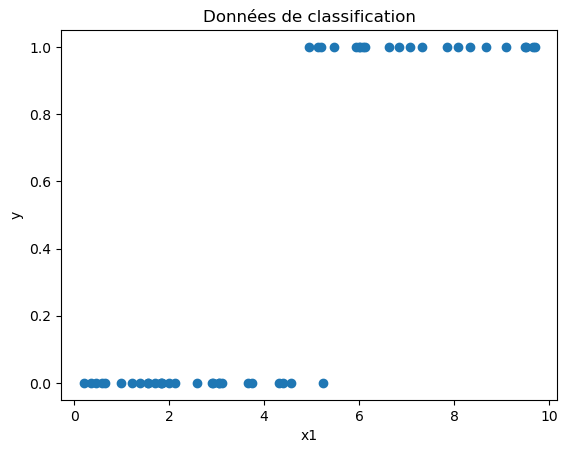

In [2]:
# Jeu de données
np.random.seed(42)
m = 50
x1 = np.random.rand(m) * 10
z = -15 + 3 * x1  # Classes plus faciles à séparer
p = 1 / (1 + np.exp(-z))
y = np.random.binomial(1, p)

plt.scatter(x1, y)
plt.xlabel('x1')
plt.ylabel('y')
plt.title('Données de classification')
plt.show()

In [3]:
# Fonction sigmoïde
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

X = np.c_[np.ones(m), x1]

**2) Régression logistique avec la descente de gradient**

Fonction de coût : $J(\theta)=-\frac{1}{m}\sum_{i=1}^{m}[y_i\log(\hat y_i)+(1-y_i)\log(1-\hat y_i)]$

In [4]:
# Initialisation
theta = np.zeros(2)       # theta_0 et theta_1
alpha = 0.1
n_iter = 5000
J_history = []

for i in range(n_iter):
    z = theta[0] + theta[1] * x1
    y_prob = sigmoid(z)

    # Fonction de coût
    eps = 1e-10
    J = -np.mean(y * np.log(y_prob + eps) + (1 - y) * np.log(1 - y_prob + eps))
    J_history.append(J)

    # Descente de gradient
    d0 = np.mean(y_prob - y)
    d1 = np.mean((y_prob - y) * x1)
    theta[0] -= alpha * d0
    theta[1] -= alpha * d1

print('theta_0 =', theta[0])
print('theta_1 =', theta[1])

theta_0 = -9.749232774057301
theta_1 = 2.0312974180456487


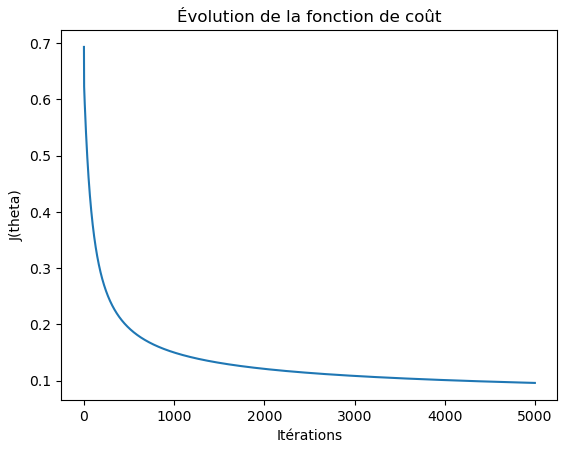

In [5]:
# Courbe du coût
plt.plot(J_history)
plt.xlabel('Itérations')
plt.ylabel('J(theta)')
plt.title('Évolution de la fonction de coût')
plt.show()

Exactitude sur les données d’entraînement : 0.98


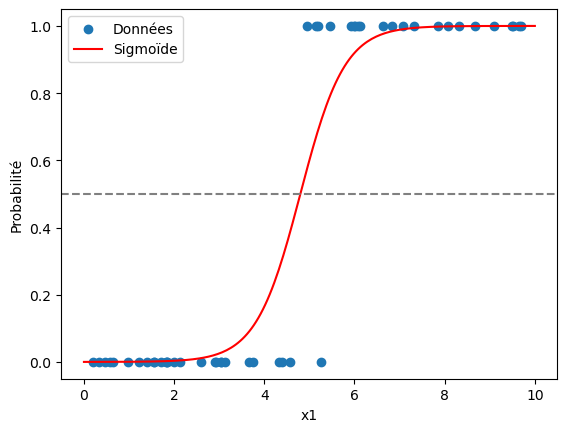

In [6]:
# Probabilités et classification (seuil = 0.5)
y_prob = sigmoid(theta[0] + theta[1] * x1)
y_pred = (y_prob >= 0.5).astype(int)
print('Exactitude sur les données d’entraînement :', np.mean(y_pred == y))

x_plot = np.linspace(0, 10, 200)
plt.scatter(x1, y, label='Données')
plt.plot(x_plot, sigmoid(theta[0] + theta[1] * x_plot), color='red', label='Sigmoïde')
plt.axhline(0.5, color='gray', linestyle='--')
plt.xlabel('x1')
plt.ylabel('Probabilité')
plt.legend()
plt.show()

In [7]:
# Matrice de confusion et métriques
TP = np.sum((y == 1) & (y_pred == 1))
TN = np.sum((y == 0) & (y_pred == 0))
FP = np.sum((y == 0) & (y_pred == 1))
FN = np.sum((y == 1) & (y_pred == 0))
precision = TP / (TP + FP) if TP + FP else 0
rappel = TP / (TP + FN) if TP + FN else 0
f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else 0
print('Matrice de confusion :')
print(np.array([[TN, FP], [FN, TP]]))
print('Précision :', precision)
print('Rappel :', rappel)
print('F1 :', f1)

Matrice de confusion :
[[27  1]
 [ 0 22]]
Précision : 0.9565217391304348
Rappel : 1.0
F1 : 0.9777777777777777


**Remarque :** l’exactitude affichée est mesurée sur les données d’entraînement. Elle ne garantit pas la performance sur de nouvelles observations. La relation simulée est volontairement plus facile à classifier.